Total Documents: 4

Tokenized Documents:
['artificial', 'intelligence', 'is', 'transforming', 'healthcare', 'machine', 'learning', 'helps', 'doctors', 'predict', 'diseases', 'ai', 'is', 'used', 'in', 'medical', 'diagnosis', 'and', 'treatment']
['deep', 'learning', 'uses', 'neural', 'networks', 'neural', 'networks', 'are', 'useful', 'for', 'image', 'recognition', 'cnn', 'is', 'commonly', 'used', 'in', 'computer', 'vision']
['python', 'is', 'a', 'programming', 'language', 'python', 'is', 'used', 'for', 'software', 'development', 'developers', 'use', 'python', 'for', 'machine', 'learning']
['natural', 'language', 'processing', 'helps', 'computers', 'understand', 'text', 'word', 'embeddings', 'represent', 'words', 'as', 'numerical', 'vectors', 'text', 'classification', 'is', 'an', 'application', 'of', 'nlp']

CBOW Model Training Completed!

Document Embeddings Shape: (4, 100)



Enter your search query:  artificial



Similarity Scores:
[0.35440567 0.23558305 0.16098198 0.28666884]

Recommended Documents:

Document: 1
Similarity: 0.3544
Artificial intelligence is transforming healthcare.
Machine learning helps doctors predict diseases.
AI is used in medical diagnosis and treatment.

Document: 4
Similarity: 0.2867
Natural language processing helps computers understand text.
Word embeddings represent words as numerical vectors.
Text classification is an application of NLP.

Document: 2
Similarity: 0.2356
Deep learning uses neural networks.
Neural networks are useful for image recognition.
CNN is commonly used in computer vision.


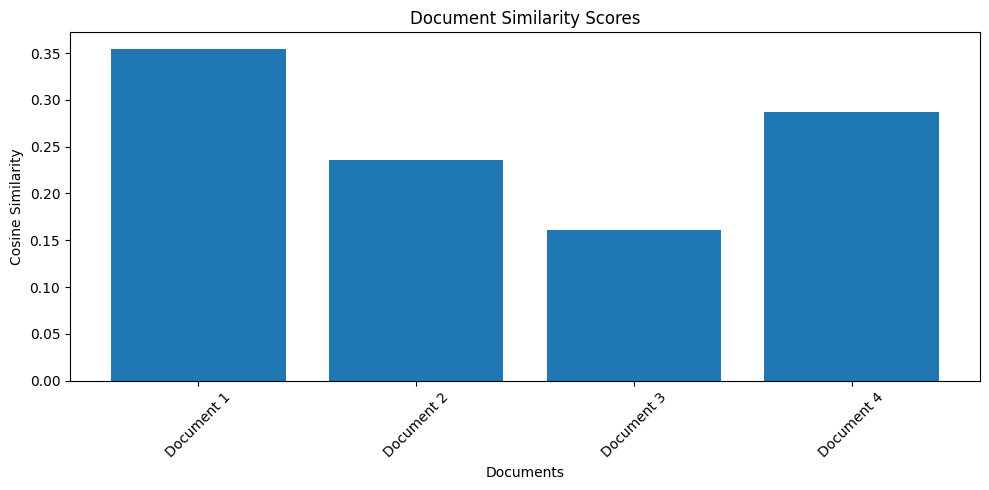

In [1]:

# STEP 1: Import Libraries

import re
import numpy as np
import matplotlib.pyplot as plt

from gensim.models import Word2Vec
from sklearn.metrics.pairwise import cosine_similarity


# STEP 2: Load Dataset

file_path = r"F:\lp4\LP IV Updated Datasets\articles.txt"  # Change this path

with open(file_path, "r", encoding="utf-8") as file:
    text = file.read()

# Each article should be separated by a blank line
documents = [doc.strip() for doc in text.split('\n\n') if doc.strip()]

print("Total Documents:", len(documents))


# STEP 3: Data Preprocessing

def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    words = text.split()
    return words

tokenized_docs = [preprocess(doc) for doc in documents]

print("\nTokenized Documents:")
for doc in tokenized_docs:
    print(doc)


# STEP 4: Train CBOW Word2Vec Model

model = Word2Vec(
    sentences=tokenized_docs,
    vector_size=100,
    window=2,
    min_count=1,
    workers=4,
    sg=0,
    epochs=100
)

print("\nCBOW Model Training Completed!")


# STEP 5: Generate Document Embeddings

def document_vector(words):
    vectors = [model.wv[word] for word in words if word in model.wv]

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)


document_vectors = np.array([
    document_vector(doc) for doc in tokenized_docs
])

print("\nDocument Embeddings Shape:", document_vectors.shape)


# STEP 6: Get User Input

user_input = input("\nEnter your search query: ")

user_words = preprocess(user_input)

user_vector = document_vector(user_words)


# STEP 7: Calculate Cosine Similarity

similarity_scores = cosine_similarity(
    [user_vector],
    document_vectors
)[0]

print("\nSimilarity Scores:")
print(similarity_scores)


# STEP 8: Recommend Similar Documents

top_indices = np.argsort(similarity_scores)[::-1][:3]

print("\nRecommended Documents:")

for index in top_indices:
    print("\nDocument:", index + 1)
    print("Similarity:", round(similarity_scores[index], 4))
    print(documents[index])


# STEP 9: Visualize Similarity Scores

plt.figure(figsize=(10, 5))

plt.bar(
    [f"Document {i+1}" for i in range(len(documents))],
    similarity_scores
)

plt.title("Document Similarity Scores")
plt.xlabel("Documents")
plt.ylabel("Cosine Similarity")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
